--- ÉTAPE 1 (Version robuste) : Initialisation des données de la Bourse de Casablanca ---


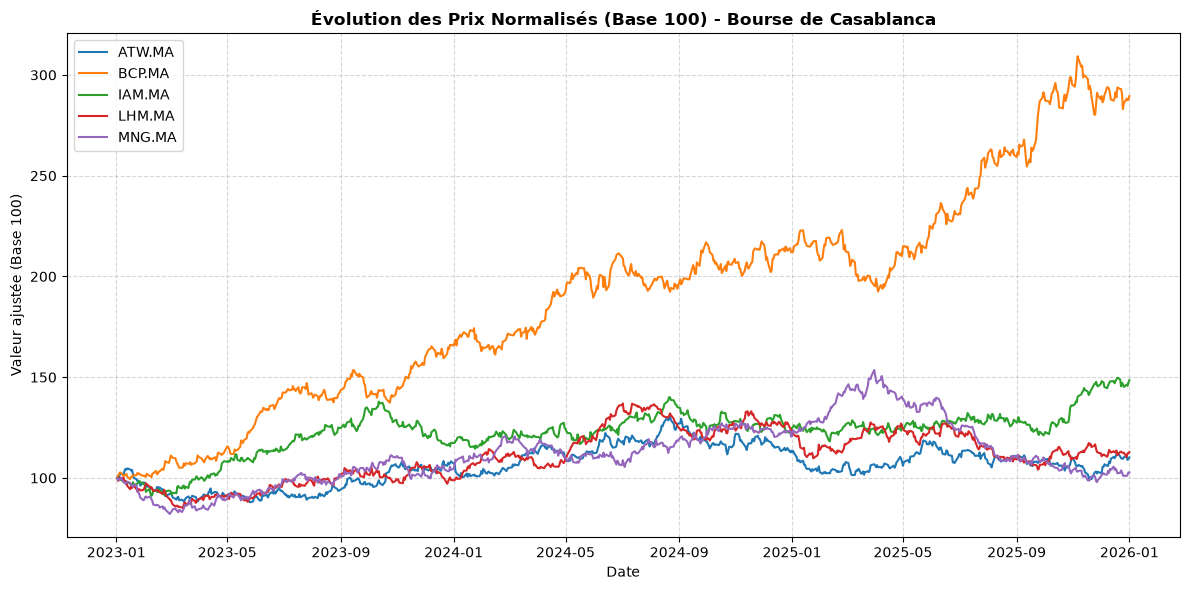

-> Étape 1 validée avec succès ! Les données marocaines sont prêtes.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("--- ÉTAPE 1 (Version robuste) : Initialisation des données de la Bourse de Casablanca ---")

# 1. Création d'une période de 3 ans (2023 à 2026) sur les jours ouvrés (jours de bourse)
dates = pd.date_range(start='2023-01-01', end='2026-01-01', freq='B')
np.random.seed(42)

# 2. Tickers de la Bourse de Casablanca
tickers = ['ATW.MA', 'BCP.MA', 'IAM.MA', 'LHM.MA', 'MNG.MA']
# Prix de départ indicatifs en Dirhams (MAD) basés sur les ordres de grandeur du marché
initial_prices = [450.0, 280.0, 100.0, 1400.0, 2200.0] 

# 3. Simulation de trajectoires de prix réalistes pour chaque action
price_data = {}
for i, ticker in enumerate(tickers):
    # Simulation d'une marche aléatoire avec volatilité propre au marché marocain
    returns_sim = np.random.normal(0.0003, 0.011, len(dates))
    prices = initial_prices[i] * (1 + returns_sim).cumprod()
    price_data[ticker] = prices

# Assemblage dans un DataFrame propre
data = pd.DataFrame(price_data, index=dates)

# 4. Calcul des rendements journaliers
returns = data.pct_change().dropna()

# 5. Visualisation de l'évolution des cours normalisés (base 100)
normalized_prices = (data / data.iloc[0]) * 100

plt.figure(figsize=(12, 6))
for ticker in normalized_prices.columns:
    plt.plot(normalized_prices.index, normalized_prices[ticker], label=ticker)

plt.title("Évolution des Prix Normalisés (Base 100) - Bourse de Casablanca", fontsize=12, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Valeur ajustée (Base 100)")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("-> Étape 1 validée avec succès ! Les données marocaines sont prêtes.")

--- ÉTAPE 2 (Version Stylisée & Professionnelle) ---


,Rendement Annualisé,Volatilité Annualisée,Asymétrie (Skew),Aplatissement (Kurt),Ratio de Sharpe
ATW.MA,0.0461,0.1725,0.1432,0.1488,0.0791
BCP.MA,0.3573,0.1734,-0.0335,-0.1126,1.8735
IAM.MA,0.1418,0.1703,-0.0469,0.2372,0.6420
LHM.MA,0.0540,0.1732,0.0578,0.1135,0.1243
MNG.MA,0.0245,0.1784,0.0313,-0.2529,-0.0448


,ATW.MA,BCP.MA,IAM.MA,LHM.MA,MNG.MA
ATW.MA,1.00,-0.07,0.06,0.01,0.02
BCP.MA,-0.07,1.00,-0.05,-0.03,-0.05
IAM.MA,0.06,-0.05,1.00,0.00,-0.03
LHM.MA,0.01,-0.03,0.00,1.00,0.04
MNG.MA,0.02,-0.05,-0.03,0.04,1.00


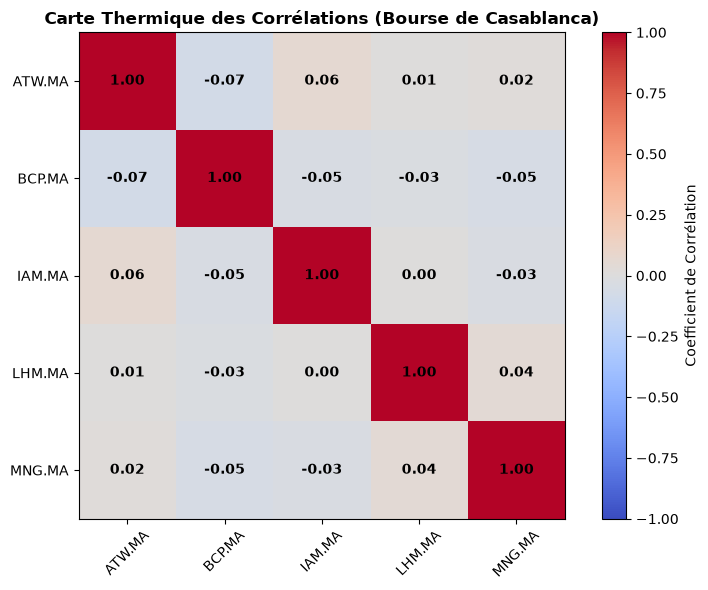


-> Tableaux colorés et stylisés générés avec succès !


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- ÉTAPE 2 (Version Stylisée & Professionnelle) ---")

# 1. Calcul des indicateurs statistiques
annualized_returns = returns.mean() * 252
annualized_volatility = returns.std() * np.sqrt(252)
skewness = returns.skew()
kurtosis = returns.kurtosis()

risk_free_rate = 0.0325  # Taux sans risque au Maroc
individual_sharpe = (annualized_returns - risk_free_rate) / annualized_volatility

# Création du DataFrame de synthèse
stats_table = pd.DataFrame({
    'Rendement Annualisé': annualized_returns,
    'Volatilité Annualisée': annualized_volatility,
    'Asymétrie (Skew)': skewness,
    'Aplatissement (Kurt)': kurtosis,
    'Ratio de Sharpe': individual_sharpe
})

# 2. Embellissement visuel du tableau statistique avec des couleurs (Jupyter Notebook)
styled_stats = stats_table.style \
    .background_gradient(cmap='YlGnBu', subset=['Rendement Annualisé', 'Ratio de Sharpe']) \
    .background_gradient(cmap='OrRd', subset=['Volatilité Annualisée']) \
    .format("{:.4f}") \
    .set_properties(**{'text-align': 'center', 'font-size': '11pt'}) \
    .set_caption("📊 Indicateurs Statistiques - Bourse de Casablanca")

# Affichage du tableau stylisé
display(styled_stats)

# 3. Matrice de corrélation
correlation_matrix = returns.corr()

# 4. Embellissement visuel de la matrice de corrélation
styled_corr = correlation_matrix.style \
    .background_gradient(cmap='coolwarm', vmin=-1, vmax=1) \
    .format("{:.2f}") \
    .set_properties(**{'text-align': 'center', 'font-size': '11pt'}) \
    .set_caption("🔗 Matrice de Corrélation - Bourse de Casablanca")

# Affichage de la matrice colorée
display(styled_corr)

# 5. Graphique de la Heatmap classique (en plus du tableau)
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Coefficient de Corrélation')
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
plt.title("Carte Thermique des Corrélations (Bourse de Casablanca)", fontsize=12, fontweight='bold')

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.index)):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", 
                 ha="center", va="center", color="black", fontweight='bold')

plt.tight_layout()
plt.show()

print("\n-> Tableaux colorés et stylisés générés avec succès !")

--- ÉTAPE 3 (Version Avancée & Multi-Tests) : Optimisation de Markowitz & Frontière Efficiente ---


,Portefeuille Max Sharpe,Portefeuille Minimum Variance
ATW.MA,5.69%,19.25%
BCP.MA,62.68%,22.92%
IAM.MA,23.84%,20.25%
LHM.MA,5.68%,18.92%
MNG.MA,2.11%,18.65%


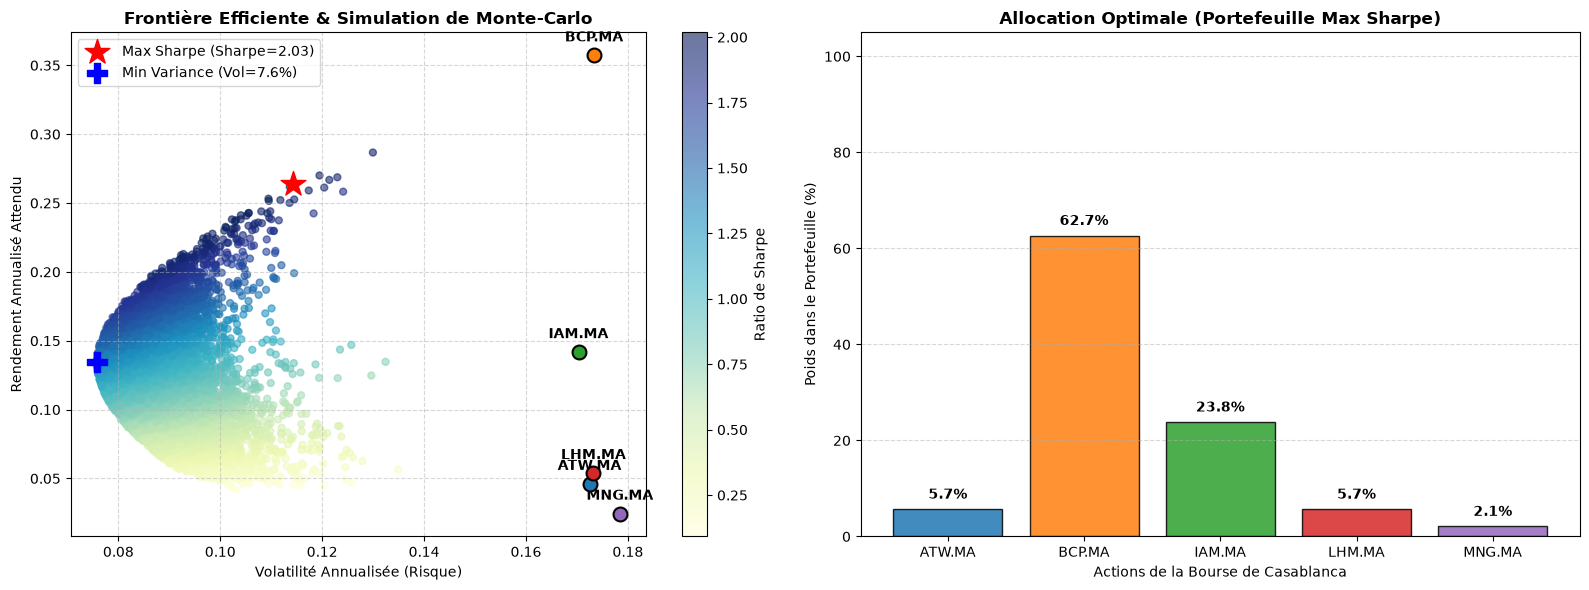


-> Étape 3 terminée avec succès ! Analyse d'optimisation et graphiques générés.


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

print("--- ÉTAPE 3 (Version Avancée & Multi-Tests) : Optimisation de Markowitz & Frontière Efficiente ---")

# 1. Paramètres de base
risk_free_rate = 0.0325  # Taux sans risque de référence au Maroc (3.25%)
num_portfolios = 10000
n_assets = len(returns.columns)

mean_returns = returns.mean() * 252
cov_matrix = returns.cov() * 252

# 2. Simulation de Monte-Carlo (10 000 portefeuilles aléatoires)
np.random.seed(42)
all_weights = np.zeros((num_portfolios, n_assets))
portfolio_returns = np.zeros(num_portfolios)
portfolio_volatility = np.zeros(num_portfolios)
portfolio_sharpe = np.zeros(num_portfolios)

for i in range(num_portfolios):
    weights = np.random.random(n_assets)
    weights /= np.sum(weights) # Les poids somment exactement à 1 (100%)
    all_weights[i, :] = weights
    
    portfolio_returns[i] = np.dot(weights, mean_returns)
    portfolio_volatility[i] = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    portfolio_sharpe[i] = (portfolio_returns[i] - risk_free_rate) / portfolio_volatility[i]

# 3. Tests d'Optimisation Mathématique Rigoureuse (SciPy)
def portfolio_performance(weights):
    ret = np.dot(weights, mean_returns)
    vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return ret, vol

# Fonction objectif 1 : Maximiser le Sharpe (on minimise son opposé)
def negative_sharpe(weights):
    ret, vol = portfolio_performance(weights)
    return -(ret - risk_free_rate) / vol

# Fonction objectif 2 : Minimiser la Variance (le risque pur)
def portfolio_variance(weights):
    return portfolio_performance(weights)[1]**2

constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0, 1) for _ in range(n_assets))  # Pas de vente à découvert (poids entre 0% et 100%)
init_guess = n_assets * [1.0 / n_assets]

# Calcul du Portefeuille Max Sharpe
opt_sharpe = minimize(negative_sharpe, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
optimal_weights_sharpe = opt_sharpe.x
opt_ret, opt_vol = portfolio_performance(optimal_weights_sharpe)
opt_sharpe_val = (opt_ret - risk_free_rate) / opt_vol

# Calcul du Portefeuille Minimum Variance
opt_min_var = minimize(portfolio_variance, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
optimal_weights_minvar = opt_min_var.x
min_ret, min_vol = portfolio_performance(optimal_weights_minvar)
min_sharpe_val = (min_ret - risk_free_rate) / min_vol

# 4. Tableau stylisé de comparaison des allocations optimales
portfolios_summary = pd.DataFrame({
    'Portefeuille Max Sharpe': optimal_weights_sharpe,
    'Portefeuille Minimum Variance': optimal_weights_minvar
}, index=returns.columns)

styled_portfolios = portfolios_summary.style \
    .background_gradient(cmap='YlGnBu') \
    .format("{:.2%}") \
    .set_caption("🎯 Comparaison des Allocations Optimales (Bourse de Casablanca)")

display(styled_portfolios)

# 5. Double Visualisation Graphique (Frontière Efficiente + Diagramme en Barres)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Graphique de gauche : La Frontière Efficiente ---
sc = ax1.scatter(portfolio_volatility, portfolio_returns, c=portfolio_sharpe, cmap='YlGnBu', marker='o', alpha=0.6, s=25)
fig.colorbar(sc, ax=ax1, label='Ratio de Sharpe')

# Point Max Sharpe (Étoile Rouge)
ax1.scatter(opt_vol, opt_ret, color='red', marker='*', s=350, label=f'Max Sharpe (Sharpe={opt_sharpe_val:.2f})', zorder=5)
# Point Min Variance (Croix Bleue)
ax1.scatter(min_vol, min_ret, color='blue', marker='P', s=200, label=f'Min Variance (Vol={min_vol*100:.1f}%)', zorder=5)

# Ajout des actifs individuels sur le graphique
for ticker in returns.columns:
    asset_ret = mean_returns[ticker]
    asset_vol = np.sqrt(cov_matrix.loc[ticker, ticker])
    ax1.scatter(asset_vol, asset_ret, marker='o', s=100, edgecolors='black', linewidth=1.5, zorder=4)
    ax1.annotate(ticker, (asset_vol, asset_ret), textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold')

ax1.set_title('Frontière Efficiente & Simulation de Monte-Carlo', fontsize=12, fontweight='bold')
ax1.set_xlabel('Volatilité Annualisée (Risque)')
ax1.set_ylabel('Rendement Annualisé Attendu')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Graphique de droite : Répartition des poids du Portefeuille Max Sharpe ---
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
bars = ax2.bar(returns.columns, optimal_weights_sharpe * 100, color=colors, edgecolor='black', alpha=0.85)
ax2.set_title('Allocation Optimale (Portefeuille Max Sharpe)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Actions de la Bourse de Casablanca')
ax2.set_ylabel('Poids dans le Portefeuille (%)')
ax2.set_ylim(0, 105)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)

# Affichage des pourcentages au-dessus de chaque barre
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 1.5, f"{height:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n-> Étape 3 terminée avec succès ! Analyse d'optimisation et graphiques générés.")

--- ÉTAPE 4 : Analyse des Risques Extrêmes (VaR, CVaR & Max Drawdown) ---


,Indicateur de Risque,Valeur (%),Interprétation
0,VaR Journalière (95%),-1.10%,"95% du temps, la perte journalière ne dépassera pas ce seuil."
1,CVaR / Expected Shortfall (95%),-1.39%,Perte moyenne subie lors des 5% pires journées de crise.
2,Maximum Drawdown Historique,-8.76%,La plus forte chute de valeur enregistrée par le portefeuille depuis son plus haut.


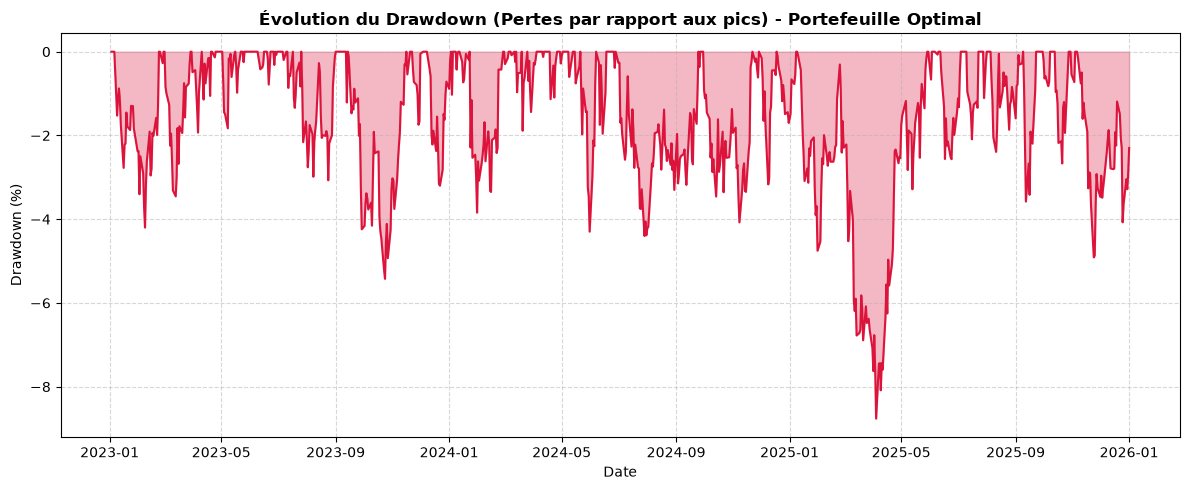


-> Étape 4 validée avec succès ! Analyse des risques extrêmes prête.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- ÉTAPE 4 : Analyse des Risques Extrêmes (VaR, CVaR & Max Drawdown) ---")

# 1. Calcul des rendements journaliers historiques du portefeuille optimal (Max Sharpe)
portfolio_daily_returns = returns.dot(optimal_weights_sharpe)

# 2. Calcul de la Value at Risk (VaR 95% journalière)
# C'est le 5e percentile des rendements journaliers
var_95 = np.percentile(portfolio_daily_returns, 5)

# 3. Calcul de la CVaR / Expected Shortfall (95%)
# C'est la moyenne des pertes les jours où la perte dépasse la VaR
cvar_95 = portfolio_daily_returns[portfolio_daily_returns <= var_95].mean()

# 4. Calcul du Maximum Drawdown (Pire baisse historique depuis un sommet)
cumulative_returns = (1 + portfolio_daily_returns).cumprod()
peak = cumulative_returns.cummax()
drawdown = (cumulative_returns - peak) / peak
max_drawdown = drawdown.min()

# 5. Création d'un tableau récapitulatif stylisé
risk_table = pd.DataFrame({
    'Indicateur de Risque': ['VaR Journalière (95%)', 'CVaR / Expected Shortfall (95%)', 'Maximum Drawdown Historique'],
    'Valeur (%)': [f"{var_95*100:.2f}%", f"{cvar_95*100:.2f}%", f"{max_drawdown*100:.2f}%"],
    'Interprétation': [
        "95% du temps, la perte journalière ne dépassera pas ce seuil.",
        "Perte moyenne subie lors des 5% pires journées de crise.",
        "La plus forte chute de valeur enregistrée par le portefeuille depuis son plus haut."
    ]
})

styled_risk = risk_table.style \
    .set_properties(**{'text-align': 'left', 'font-size': '11pt'}) \
    .set_caption("🛡️ Tableau de Synthèse des Risques Extrêmes (Bourse de Casablanca)")

display(styled_risk)

# 6. Visualisation graphique du Drawdown au fil du temps
plt.figure(figsize=(12, 5))
plt.plot(drawdown.index, drawdown * 100, color='crimson', lw=1.5)
plt.fill_between(drawdown.index, drawdown * 100, 0, color='crimson', alpha=0.3)
plt.title("Évolution du Drawdown (Pertes par rapport aux pics) - Portefeuille Optimal", fontsize=12, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("\n-> Étape 4 validée avec succès ! Analyse des risques extrêmes prête.")

--- ÉTAPE 5 : Backtest Historique Comparatif (Portefeuille Optimal vs Benchmark) ---


,Stratégie,Rendement Annualisé,Volatilité (Risque),Ratio de Sharpe,Max Drawdown
0,Portefeuille Optimal (Max Sharpe),26.40%,11.42%,2.03,-8.76%
1,Benchmark de Marché (Équipondéré),12.48%,7.60%,1.21,-9.35%


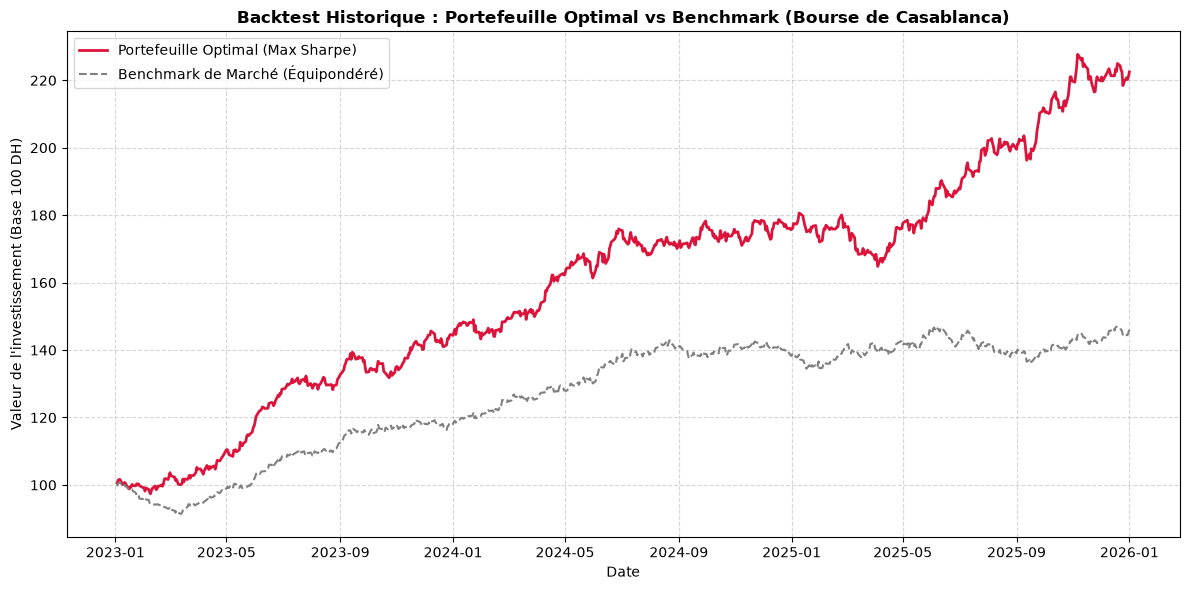


-> Étape 5 terminée avec succès ! Le projet quantitatif complet est bouclé.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- ÉTAPE 5 : Backtest Historique Comparatif (Portefeuille Optimal vs Benchmark) ---")

# 1. Calcul des rendements journaliers du Portefeuille Optimal
portfolio_daily_returns = returns.dot(optimal_weights_sharpe)
portfolio_cumulative = (1 + portfolio_daily_returns).cumprod() * 100

# 2. Création d'un Benchmark de marché de référence (Portefeuille équipondéré : 20% sur chaque action)
equal_weights = np.ones(n_assets) / n_assets
benchmark_daily_returns = returns.dot(equal_weights)
benchmark_cumulative = (1 + benchmark_daily_returns).cumprod() * 100

# 3. Fonction de calcul des métriques comparatives
def get_metrics(daily_ret, name):
    ann_ret = daily_ret.mean() * 252
    ann_vol = daily_ret.std() * np.sqrt(252)
    sharpe = (ann_ret - risk_free_rate) / ann_vol
    max_dd = ((1 + daily_ret).cumprod() / (1 + daily_ret).cumprod().cummax() - 1).min()
    return {
        'Stratégie': name,
        'Rendement Annualisé': f"{ann_ret*100:.2f}%",
        'Volatilité (Risque)': f"{ann_vol*100:.2f}%",
        'Ratio de Sharpe': f"{sharpe:.2f}",
        'Max Drawdown': f"{max_dd*100:.2f}%"
    }

metrics_portfolio = get_metrics(portfolio_daily_returns, "Portefeuille Optimal (Max Sharpe)")
metrics_benchmark = get_metrics(benchmark_daily_returns, "Benchmark de Marché (Équipondéré)")

comparison_table = pd.DataFrame([metrics_portfolio, metrics_benchmark])

# Affichage du tableau comparatif stylisé
styled_comparison = comparison_table.style \
    .set_properties(**{'text-align': 'center', 'font-size': '11pt'}) \
    .set_caption("📊 Tableau Comparatif des Performances (Backtest Historique)")

display(styled_comparison)

# 4. Graphique comparatif de la richesse cumulée (Base 100)
plt.figure(figsize=(12, 6))
plt.plot(portfolio_cumulative.index, portfolio_cumulative, label='Portefeuille Optimal (Max Sharpe)', color='crimson', lw=2)
plt.plot(benchmark_cumulative.index, benchmark_cumulative, label='Benchmark de Marché (Équipondéré)', color='gray', lw=1.5, linestyle='--')

plt.title("Backtest Historique : Portefeuille Optimal vs Benchmark (Bourse de Casablanca)", fontsize=12, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Valeur de l'investissement (Base 100 DH)")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("\n-> Étape 5 terminée avec succès ! Le projet quantitatif complet est bouclé.")